<a href="https://colab.research.google.com/github/KP-365/hybrid-ope-lending/blob/main/XGBModel/Model2propensity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Outcome model (model 2)
Predicts whether an accepted loan defaults. DR uses it as the "guess" for **every** applicant, including rejected ones, so it only uses the shared features model 1 used.

## Setup
Mount Drive, import libraries and load the outcome dataset (358,894 finished loans, 2007–2014).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import accuracy_score, log_loss
import numpy as np
from sklearn.calibration import calibration_curve
from matplotlib import pyplot as plt

In [3]:
DATA_DIR = '/content/drive/MyDrive/hybrid-ope-lending'
outcome_df = pd.read_parquet(f'{DATA_DIR}/lending_club_outcome.parquet')

In [4]:
outcome_df

,id,amount,date,purpose,risk_score,dti,zip3,state,emp_length,year,...,lc_purpose,revol_bal,revol_util,open_acc,total_acc,delinq_2yrs,inq_last_6mths,pub_rec,mort_acc,default
0,36805548.0,10400.0,2014-12-01,credit_card,712.0,14.92,937,CA,8 years,2014,...,credit_card,6133.0,31.6,17.0,36.0,0.0,2.0,0.0,1.0,1
1,37822187.0,9600.0,2014-12-01,debt_consolidation,682.0,25.81,077,NJ,10+ years,2014,...,debt_consolidation,16388.0,59.4,12.0,44.0,0.0,0.0,0.0,0.0,0
2,37662224.0,7650.0,2014-12-01,debt_consolidation,687.0,34.81,850,AZ,< 1 year,2014,...,debt_consolidation,16822.0,91.9,11.0,20.0,0.0,1.0,0.0,0.0,1
3,37682226.0,17000.0,2014-12-01,debt_consolidation,677.0,23.63,144,NY,10+ years,2014,...,debt_consolidation,5063.0,46.4,7.0,31.0,0.0,0.0,0.0,2.0,0
4,36804663.0,23325.0,2014-12-01,credit_card,667.0,27.03,982,WA,10+ years,2014,...,credit_card,32372.0,82.2,14.0,23.0,1.0,0.0,0.0,6.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358889,1062400.0,20500.0,2012-01-01,debt_consolidation,702.0,16.40,100,NY,7 years,2012,...,debt_consolidation,15417.0,58.4,10.0,20.0,1.0,3.0,0.0,NaN,0
358890,1059394.0,15000.0,2012-01-01,small_business,682.0,8.35,900,CA,3 years,2012,...,small_business,8897.0,33.1,18.0,30.0,2.0,1.0,0.0,NaN,0
358891,1059224.0,35000.0,2012-01-01,small_business,722.0,4.90,922,CA,3 years,2012,...,small_business,23665.0,62.4,9.0,17.0,0.0,1.0,0.0,NaN,0
358892,1058722.0,12000.0,2012-01-01,other,677.0,12.93,770,TX,None,2012,...,other,15006.0,93.2,14.0,27.0,0.0,0.0,0.0,NaN,1


## Features
The same shared features as model 1 (rejected applicants don't have the extra columns), plus the target `default`.

In [5]:
features = ['amount', 'purpose', 'risk_score', 'dti', 'zip3', 'state', 'year', 'month', 'default']

In [6]:
model_ds = outcome_df[features]

In [7]:
model_ds

,amount,purpose,risk_score,dti,zip3,state,year,month,default
0,10400.0,credit_card,712.0,14.92,937,CA,2014,12,1
1,9600.0,debt_consolidation,682.0,25.81,077,NJ,2014,12,0
2,7650.0,debt_consolidation,687.0,34.81,850,AZ,2014,12,1
3,17000.0,debt_consolidation,677.0,23.63,144,NY,2014,12,0
4,23325.0,credit_card,667.0,27.03,982,WA,2014,12,1
...,...,...,...,...,...,...,...,...,...
358889,20500.0,debt_consolidation,702.0,16.40,100,NY,2012,1,0
358890,15000.0,small_business,682.0,8.35,900,CA,2012,1,0
358891,35000.0,small_business,722.0,4.90,922,CA,2012,1,0
358892,12000.0,other,677.0,12.93,770,TX,2012,1,1


Set column types: zip, state, month and purpose as categories.

In [8]:
model_ds['zip3'] = model_ds['zip3'].astype('category')
model_ds['state'] = model_ds['state'].astype('category')
model_ds['year'] = model_ds['year'].astype('int')
model_ds['month'] = model_ds['month'].astype('category')
model_ds['purpose'] = model_ds['purpose'].astype('category')


/tmp/ipykernel_3423/1102010130.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_ds['zip3'] = model_ds['zip3'].astype('category')
/tmp/ipykernel_3423/1102010130.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  model_ds['state'] = model_ds['state'].astype('category')
/tmp/ipykernel_3423/1102010130.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pa

**Fixed:** the last line previously set `purpose` from `month`, so the model never saw the real purpose. **The outputs below are from before this fix; rerun the notebook to update them.**

Same fixes as model 1: applicants with a risk score only, and scores banded into 5-point groups. All 358,894 loans have a score.

In [9]:

scored_outcome = model_ds[model_ds['risk_score'].notna()].copy()
scored_outcome['risk_score'] = scored_outcome['risk_score'] // 5 * 5

len(scored_outcome)


358894

Split by time: train 2007–2013, test 2014.

In [10]:
train = scored_outcome[scored_outcome['year'] < 2014]
test = scored_outcome[scored_outcome['year'] == 2014]

In [11]:
train

,amount,purpose,risk_score,dti,zip3,state,year,month,default
162570,5000.0,major_purchase,735.0,27.65,860,AZ,2011,12,0
162571,2500.0,other,740.0,1.00,309,GA,2011,12,1
162572,2400.0,house,735.0,8.72,606,IL,2011,12,0
162573,10000.0,other,690.0,20.00,917,CA,2011,12,0
162574,3000.0,other,695.0,17.94,972,OR,2011,12,0
...,...,...,...,...,...,...,...,...,...
358889,20500.0,debt_consolidation,700.0,16.40,100,NY,2012,1,0
358890,15000.0,small_business,680.0,8.35,900,CA,2012,1,0
358891,35000.0,small_business,720.0,4.90,922,CA,2012,1,0
358892,12000.0,other,675.0,12.93,770,TX,2012,1,1


Overall default rate: **13.9%**.

In [12]:
len(scored_outcome[scored_outcome['default'] == 1]) / len(scored_outcome)

0.1386704709468534

Separate the features (X) from the target (y).

In [13]:
X_test = test.drop('default', axis=1)
y_test = test['default']
X_train = train.drop('default', axis=1)
y_train = train['default']

## Baseline
Log loss of predicting the training default rate for everyone: **0.400**. A useful model must beat this.

In [14]:
baseline = np.full(len(y_test), y_train.mean())
log_loss(y_test, baseline)

0.3999931223795231

## First model (default settings)

In [15]:
model = xgb.XGBClassifier(tree_method='hist', enable_categorical=True,)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_test)
log_loss(y_test, y_pred)

0.42216954333365847

In [16]:
train_pred = model.predict_proba(X_train)
log_loss(y_train, train_pred)

0.2941540671574042

**Before the purpose fix:** test log loss 0.420 (worse than the 0.400 baseline) vs 0.302 on training data: overfitting.** It memorised the training years instead of learning general patterns.

Calibration curve:

In [17]:
calibration = calibration_curve(y_test, y_pred[:, 1])

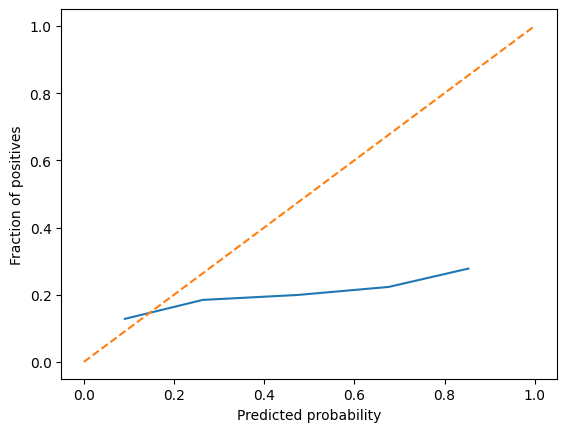

In [29]:

plt.plot(calibration[1], calibration[0])
plt.plot([0,1], [0,1], linestyle = '--')
plt.xlabel('Predicted probability')
plt.ylabel('Fraction of positives')
plt.show()

*`calibration_curve` returns (actual rate, predicted); the plot now puts predicted on x and actual on y, matching the labels (the image below is from before this fix).*

Predictions range from 9% to 85% while actual default rates are only 13–24%: **badly overconfident**, consistent with overfitting.

## Simpler model
Shallower trees (`max_depth=3`), slower learning (`learning_rate=0.05`) and at least 50 loans per leaf (`min_child_weight=50`), to stop it memorising the training years.

In [19]:
simple_model = xgb.XGBClassifier(tree_method='hist', enable_categorical=True, max_depth=3, learning_rate = 0.05, min_child_weight = 50)
simple_model.fit(X_train, y_train)
simple_y_pred = simple_model.predict_proba(X_test)


**Before the purpose fix: test log loss 0.391 vs 0.400 baseline, about 2% better.** A small gain is normal for default prediction: Lending Club had already screened out the obviously risky applicants, and only shared features are used.

In [20]:
log_loss(y_test, simple_y_pred)

0.39072632101929594

In [21]:
log_loss(y_test, simple_y_pred)

0.39072632101929594

Calibration curve (axes labelled correctly here: x = actual default rate, y = predicted):

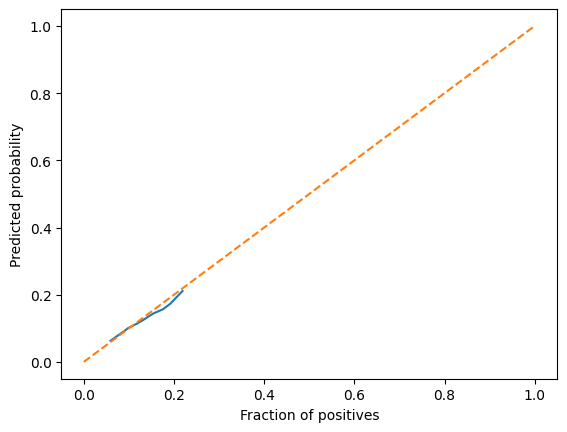

In [27]:
simple_calibration = calibration_curve(y_test, simple_y_pred[:, 1], n_bins=10, strategy='quantile' )

plt.plot(simple_calibration[0], simple_calibration[1])
plt.plot([0,1], [0,1], linestyle = '--')
plt.xlabel('Predicted probability')
plt.ylabel('Fraction of positives')
plt.show()

**On the diagonal: well calibrated.** Predictions range from about 6% to 22%, matching the actual default rates. That's what DR needs from the outcome model.

Save the model to Drive for the DR step.

In [23]:
simple_model.save_model('/content/drive/MyDrive/hybrid-ope-lending/outcome_model.json')